# Proyecto Computación I – Gemelo Digital de Aruba (módulo energético)
## Análisis exploratorio (EDA) y coherencia entre fuentes — v2

**Fuentes usadas** (rutas relativas a la raíz del repositorio):

| # | Fichero | Contenido |
|---|---|---|
| 1 | `data/raw/aruba_stations.json` | Metadatos de las 12 estaciones |
| 2 | `data/raw/train_aruba_lecturas.json` | Lecturas de las estaciones cada 5 min (no versionado, ver `data/README.md`) |
| 3 | `data/external/datos_meteo.csv` | Reanálisis ERA5 horario 2026, 9 puntos de rejilla (viento 10/100 m, temperatura, presión, radiación, nubosidad, capa límite, rachas) |
| 4 | `data/external/turbinas.json` | Ficha técnica Vestas V90‑3.0 (aerogenerador de Vader Piet) |
| 5 | `data/external/equipment_installed.json` | Capacidad instalada del sistema eléctrico y demanda 2026 |
| 6 | `data/external/historical_figures.json` | Producción anual histórica del parque eólico 2010‑2025 |
| 7 | `data/external/outage_performance.json` | Duración anual de interrupciones 2020‑2025 |

**Objetivo de esta versión:** comprobar si las fuentes son **coherentes entre sí** (periodos, unidades, husos horarios, magnitudes físicas)
y medir sus **correlaciones**, para decidir cómo construir el viento a altura de buje, la potencia y los umbrales (OE‑01, OE‑02, RF‑02…RF‑05, RF‑08).

## 0. Configuración

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60, "display.width", 180)

# Raíz del repo: la primera carpeta hacia arriba que contenga data/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
RAW, EXT = ROOT / "data" / "raw", ROOT / "data" / "external"
PATH_STATIONS = RAW / "aruba_stations.json"
PATH_LECTURAS = RAW / "train_aruba_lecturas.json"
PATH_METEO    = EXT / "datos_meteo.csv"
PATH_TURBINA  = EXT / "turbinas.json"
PATH_EQUIPOS  = EXT / "equipment_installed.json"
PATH_HISTORICO = EXT / "historical_figures.json"
PATH_CORTES   = EXT / "outage_performance.json"

TZ_LOCAL = "America/Aruba"          # UTC-4, sin horario de verano
ALTURA_ESTACION_M = 10              # SUPUESTO: altura del anemómetro (se contrasta con ERA5 a 10 m)
UMBRAL_ALERTA_KW = 500              # RF-13
PARQUE_LATLON = (12.47, -69.93)     # SUPUESTO: ubicación aproximada de Vader Piet (costa sureste)

faltan = [p.name for p in (PATH_STATIONS, PATH_LECTURAS, PATH_METEO, PATH_TURBINA, PATH_EQUIPOS, PATH_HISTORICO, PATH_CORTES) if not p.exists()]
assert not faltan, f"Faltan ficheros: {faltan}"
print("Raíz del proyecto:", ROOT)

Raíz del proyecto: C:\Users\GAMER\Desktop\UEM\Proyecto de computacion I\Github Repo\PROYECTO_COMP_I


## 1. Fuentes externas del sistema eléctrico y de la turbina

In [2]:
turb = json.loads(PATH_TURBINA.read_text(encoding="utf-8"))
equip = json.loads(PATH_EQUIPOS.read_text(encoding="utf-8"))["equipment_installed_capacity"]
hist = pd.DataFrame(json.loads(PATH_HISTORICO.read_text(encoding="utf-8"))["historic_figures"]).sort_values("year")
cortes = pd.DataFrame(json.loads(PATH_CORTES.read_text(encoding="utf-8"))["outage_performance"]).sort_values("year")

num = lambda s: float(str(s).split()[0].replace(",", ""))
ficha = turb["hoja_de_datos"]
P_NOMINAL_KW = num(ficha["De energía"]["Potencia nominal"])
V_ARRANQUE   = num(ficha["De energía"]["Velocidad del viento"])
V_NOMINAL    = num(ficha["De energía"]["Velocidad nominal del viento"])
V_CORTE      = num(ficha["De energía"]["Velocidad del viento de corte"])
D_ROTOR      = num(ficha["Hélice"]["diámetro"])
alturas_buje = [float(x) for x in ficha["Torre"]["Altura del buje"].split()[0].split("/")]
ALTURA_BUJE_M = alturas_buje[0]     # SUPUESTO: 80 m (la ficha da 80/105 m)

CAP_EOLICA_MW = equip["renewables"]["wind_turbines_wp_vaderpiet"]["capacity_mw"]
N_TURBINAS = round(CAP_EOLICA_MW * 1000 / P_NOMINAL_KW)
print(f"Turbina {turb['nombre']}: {P_NOMINAL_KW:.0f} kW | arranque {V_ARRANQUE} m/s | nominal {V_NOMINAL} m/s | corte {V_CORTE} m/s | rotor {D_ROTOR} m | buje {alturas_buje} m")
print(f"Parque: {CAP_EOLICA_MW} MW / {P_NOMINAL_KW/1000:.0f} MW = {N_TURBINAS} turbinas")

Turbina Vestas V90-3.0: 3000 kW | arranque 4.0 m/s | nominal 15.0 m/s | corte 25.0 m/s | rotor 90.0 m | buje [80.0, 105.0] m
Parque: 30.0 MW / 3 MW = 10 turbinas


### 1.1 Coherencia interna de los ficheros del sistema eléctrico

In [3]:
th = equip["firm_capacity_thermal"]; ren = equip["renewables"]; dem = equip["load_demand_2026"]
suma_term = sum(v["capacity_mw"] for k, v in th.items() if isinstance(v, dict))
suma_ren = sum(v["capacity_mw"] for k, v in ren.items() if isinstance(v, dict))
checks = pd.DataFrame([
    ["Suma térmica = total firme", suma_term, th["total_firm_capacity_mw"]],
    ["Suma renovables = total renovables", suma_ren, ren["total_renewables_mw"]],
    ["Firme térmica ≥ pico de demanda", th["total_firm_capacity_mw"], dem["max_peak_mw"]],
    ["Renovable instalada vs demanda media", ren["total_renewables_mw"], dem["average_mw"]],
], columns=["comprobación", "valor A (MW)", "valor B (MW)"])
checks["coherente"] = [np.isclose(suma_term, th["total_firm_capacity_mw"]), np.isclose(suma_ren, ren["total_renewables_mw"]),
                       th["total_firm_capacity_mw"] >= dem["max_peak_mw"], True]
display(checks)
print(f"Margen de reserva térmica sobre el pico: {th['total_firm_capacity_mw'] - dem['max_peak_mw']:.1f} MW "
      f"({th['total_firm_capacity_mw']/dem['max_peak_mw']-1:.0%})")
print(f"La eólica a plena carga cubre como máximo el {CAP_EOLICA_MW/dem['average_mw']:.1%} de la demanda media "
      f"y el {CAP_EOLICA_MW/dem['max_peak_mw']:.1%} del pico.")
print(f"Umbral RF-13 ({UMBRAL_ALERTA_KW} kW) = {UMBRAL_ALERTA_KW/(CAP_EOLICA_MW*1000):.1%} de la capacidad del parque "
      f"= {UMBRAL_ALERTA_KW/P_NOMINAL_KW:.1%} de una turbina.")

,comprobación,valor A (MW),valor B (MW),coherente
0,Suma térmica = total firme,252.4,252.4,True
1,Suma renovables = total renovables,36.1,36.1,True
2,Firme térmica ≥ pico de demanda,252.4,172.0,True
3,Renovable instalada vs demanda media,36.1,121.0,True


Margen de reserva térmica sobre el pico: 80.4 MW (47%)
La eólica a plena carga cubre como máximo el 24.8% de la demanda media y el 17.4% del pico.
Umbral RF-13 (500 kW) = 1.7% de la capacidad del parque = 16.7% de una turbina.


,year,production_mwh,capacity_percent,cf_recalculado_%,dif_pp,potencia_media_mw
15,2010,106742,40.6,40.62,0.02,12.19
14,2011,112765,42.9,42.91,0.01,12.87
13,2012,135155,51.4,51.43,0.03,15.43
12,2013,150811,57.4,57.39,-0.01,17.22
11,2014,161506,61.5,61.46,-0.04,18.44
10,2015,175244,66.7,66.68,-0.02,20.01
9,2016,145432,55.3,55.34,0.04,16.60
8,2017,139034,52.9,52.90,0.00,15.87
7,2018,160924,61.2,61.23,0.03,18.37
6,2019,150328,57.2,57.20,0.00,17.16


Diferencia máxima entre CF declarado y recalculado: 0.04 pp → 'capacity_percent' es el factor de capacidad del parque de 30 MW.
Factor de capacidad histórico: media 53.0 % | rango 40.6–66.7 % | último año 53.0 %
Cuota eólica sobre la demanda media 2026 (con la producción 2025): 13.1%


,year,total_outage_duration,remaining_outage_allowance,interrupcion_h,margen_h,suma_h
5,2020,7:37 hours,16:23 hours,7.62,16.38,24.0
4,2021,19:39 hours,4:21 hours,19.65,4.35,24.0
3,2022,21:16 hours,2:44 hours,21.27,2.73,24.0
2,2023,6:28 hours,17:32 hours,6.47,17.53,24.0
1,2024,11:27 hours,12:33 hours,11.45,12.55,24.0
0,2025,7:17 hours,16:43 hours,7.28,16.72,24.0


Interrupción + margen = 24 h en todos los años: True
Correlación (Pearson, n=6) producción eólica vs horas de interrupción: -0.33  (muestra muy pequeña: solo indicativa)


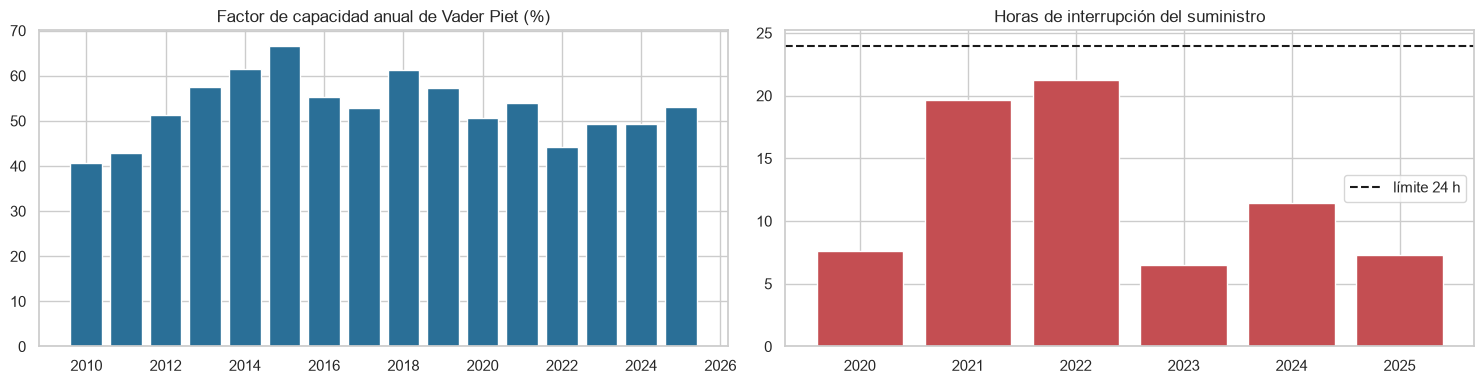

In [4]:
# Históricos de producción: ¿el % de capacidad declarado es coherente con 30 MW?
hist["cf_recalculado_%"] = hist.production_mwh / (CAP_EOLICA_MW * 8760) * 100
hist["dif_pp"] = (hist["cf_recalculado_%"] - hist.capacity_percent).round(2)
hist["potencia_media_mw"] = hist.production_mwh / 8760
display(hist.round(2))
print(f"Diferencia máxima entre CF declarado y recalculado: {hist.dif_pp.abs().max():.2f} pp "
      "→ 'capacity_percent' es el factor de capacidad del parque de 30 MW.")
print(f"Factor de capacidad histórico: media {hist.capacity_percent.mean():.1f} % | "
      f"rango {hist.capacity_percent.min():.1f}–{hist.capacity_percent.max():.1f} % | último año {hist.capacity_percent.iloc[-1]:.1f} %")
print(f"Cuota eólica sobre la demanda media 2026 (con la producción 2025): "
      f"{hist.production_mwh.iloc[-1] / (dem['average_mw']*8760):.1%}")

def a_horas(s):
    h, m = str(s).split()[0].split(":"); return int(h) + int(m) / 60
cortes["interrupcion_h"] = cortes.total_outage_duration.map(a_horas)
cortes["margen_h"] = cortes.remaining_outage_allowance.map(a_horas)
cortes["suma_h"] = cortes.interrupcion_h + cortes.margen_h
display(cortes.round(2))
print("Interrupción + margen = 24 h en todos los años:", bool(np.allclose(cortes.suma_h, 24)))

h2 = hist.merge(cortes[["year", "interrupcion_h"]], on="year")
print(f"Correlación (Pearson, n={len(h2)}) producción eólica vs horas de interrupción: "
      f"{h2.production_mwh.corr(h2.interrupcion_h):.2f}  (muestra muy pequeña: solo indicativa)")

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].bar(hist.year, hist.capacity_percent, color="#2a6f97"); ax[0].set_title("Factor de capacidad anual de Vader Piet (%)")
ax[1].bar(cortes.year, cortes.interrupcion_h, color="#c44e52"); ax[1].axhline(24, ls="--", c="k", label="límite 24 h")
ax[1].set_title("Horas de interrupción del suministro"); ax[1].legend()
plt.tight_layout(); plt.show()

## 2. Estaciones y lecturas

In [5]:
stations = pd.read_json(PATH_STATIONS)
lect = pd.read_json(PATH_LECTURAS, convert_dates=False)
lect["timestamp"] = pd.to_datetime(lect["timestamp"], utc=True, errors="coerce")
print("Estaciones:", stations.shape, "| Lecturas:", lect.shape)
display(stations)
display(lect.head())

Estaciones: (12, 8) | Lecturas: (421584, 11)


,id,name,code,latitude,longitude,elevation_m,district,is_active
0,4ca4c103-894d-4f59-a911-f3abb8077e3c,Alto Vista,WS-ALT-11,12.5912,-70.0374,25,Noord,True
1,de2ee07b-de63-49db-a669-64177a688bbf,Queen Beatrix Airport,WS-APT-02,12.5042,-70.0031,18,Oranjestad,True
2,acb2fa5c-518a-4a38-b68d-bf8e3b041ccf,Arikok National Park,WS-ARK-10,12.5009,-69.9538,120,Santa Cruz,True
3,f678bd98-07d3-459d-bd4d-7aaba7051847,Hooiberg Summit,WS-HOO-07,12.5204,-69.9992,165,Santa Cruz,True
4,8f0185fa-a4c3-41c1-8f3b-d08f4f6aece0,Malmok,WS-MAL-12,12.5961,-70.0489,6,Noord,True
5,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,Noord,WS-NRD-03,12.5645,-70.0319,15,Noord,True
6,c3a0e9a3-36fe-4c50-8c3e-e100045b4a63,Oranjestad Central,WS-ORA-01,12.5201,-70.0371,5,Oranjestad,True
7,5c5c4158-91cb-4073-ab4c-9bb10037dc16,Paradera,WS-PAR-06,12.5354,-70.0050,30,Paradera,True
8,d8a1ce0a-873e-436f-9c1d-a2179ee2601c,Palm Beach,WS-PLM-04,12.5626,-70.0417,3,Noord,True
9,82a31d3a-9895-42e5-8ea0-11e8cb15b964,Savaneta,WS-SAV-08,12.4526,-69.9497,4,Savaneta,True


,id,station_id,timestamp,temperature_c,humidity_pct,wind_speed_kmh,wind_direction_deg,pressure_hpa,precipitation_mm,visibility_km,uv_index
0,7d227091-7c79-43e2-ad53-ba4bb2a20299,09ea9cd3-4d28-4049-9dfb-3c5bd5849e9c,2026-03-31 22:00:00+00:00,30.5,71.6,21.2,45.3,1016.0,0.0,11.7,0.0
1,5b9f3e1c-e410-4bc7-a0f5-ef4752ddfee9,4ca4c103-894d-4f59-a911-f3abb8077e3c,2026-03-31 22:00:00+00:00,30.4,71.8,21.5,45.6,1016.0,0.0,12.3,0.0
2,030f90af-d5fd-4554-bc71-5d947ba5663e,5c5c4158-91cb-4073-ab4c-9bb10037dc16,2026-03-31 22:00:00+00:00,30.1,71.8,22.1,46.2,1016.0,0.0,11.9,0.0
3,39b0eab6-66c8-4a5c-987b-63a119e533d1,82a31d3a-9895-42e5-8ea0-11e8cb15b964,2026-03-31 22:00:00+00:00,30.3,71.7,20.8,45.4,1016.0,0.0,11.8,0.0
4,50708c07-12b0-4c63-8a82-7527e03e6f2a,8f0185fa-a4c3-41c1-8f3b-d08f4f6aece0,2026-03-31 22:00:00+00:00,30.5,71.7,20.7,45.0,1016.0,0.0,12.2,0.0


### 2.1 Calidad: nulos, duplicados e integridad referencial (RF-01, RF-03)

In [6]:
display(pd.DataFrame({"nulos": lect.isna().sum(), "% nulos": (lect.isna().mean()*100).round(2), "únicos": lect.nunique()}))
VARS = ["temperature_c", "humidity_pct", "wind_speed_kmh", "wind_direction_deg",
        "pressure_hpa", "precipitation_mm", "visibility_km", "uv_index"]

dup_mask = lect.duplicated(["station_id", "timestamp"], keep=False)
print("Duplicados por id:                    ", lect["id"].duplicated().sum())
print("Filas extra por (station_id, timestamp):", lect.duplicated(["station_id", "timestamp"]).sum())
print("Timestamps no parseables:             ", lect["timestamp"].isna().sum())
# ¿Los duplicados son copias exactas o lecturas contradictorias?
g = lect[dup_mask].groupby(["station_id", "timestamp"])[VARS].nunique()
contradictorios = (g > 1).any(axis=1)
print(f"Grupos duplicados: {len(g)} | con valores distintos entre copias: {contradictorios.sum()} ({contradictorios.mean():.1%})")
if contradictorios.any():
    print("Variables que difieren dentro de los duplicados (% de grupos):")
    display((g > 1).mean().mul(100).round(1).to_frame("% grupos"))

huerfanas = set(lect["station_id"]) - set(stations["id"])
print("station_id sin estación:", len(huerfanas), "| estaciones sin lecturas:", len(set(stations["id"]) - set(lect["station_id"])))
print("Estaciones inactivas:", stations.loc[~stations["is_active"], "name"].tolist())

,nulos,% nulos,únicos
id,0,0.0,421584
station_id,0,0.0,12
timestamp,0,0.0,26204
temperature_c,0,0.0,135
humidity_pct,0,0.0,353
wind_speed_kmh,0,0.0,411
wind_direction_deg,0,0.0,552
pressure_hpa,0,0.0,172
precipitation_mm,0,0.0,86
visibility_km,0,0.0,85


Duplicados por id:                     0
Filas extra por (station_id, timestamp): 107136
Timestamps no parseables:              0


Grupos duplicados: 107136 | con valores distintos entre copias: 0 (0.0%)


station_id sin estación: 0 | estaciones sin lecturas: 0
Estaciones inactivas: []


In [7]:
# Limpieza mínima para el EDA: duplicados -> media de las copias (no se descarta información de forma arbitraria)
lect = (lect.dropna(subset=["timestamp"])
            .groupby(["station_id", "timestamp"], as_index=False)[VARS].mean()
            .sort_values(["station_id", "timestamp"]).reset_index(drop=True))
df = lect.merge(stations.rename(columns={"id": "station_id", "name": "station"}), on="station_id", how="left")
df["wind_ms"] = df["wind_speed_kmh"] / 3.6
df["local_time"] = df["timestamp"].dt.tz_convert(TZ_LOCAL)
df["hour_utc"] = df["timestamp"].dt.hour
T0, T1 = df["timestamp"].min(), df["timestamp"].max()
print("Lecturas limpias:", df.shape, "| periodo:", T0, "→", T1, f"({(T1-T0).days} días)")

Lecturas limpias: (314448, 20) | periodo: 2026-03-31 22:00:00+00:00 → 2026-06-30 21:35:00+00:00 (90 días)


### 2.2 Frecuencia de muestreo y huecos

In [8]:
dt = df.groupby("station_id")["timestamp"].diff().dropna().dt.total_seconds() / 60
display(dt.value_counts().head(6).to_frame("n").rename_axis("intervalo (min)"))
display(df.groupby("station").agg(n=("timestamp", "size"), inicio=("timestamp", "min"), fin=("timestamp", "max"),
                                  elev=("elevation_m", "first"), distrito=("district", "first")).sort_values("elev"))
print("Huecos > 15 min:", int((dt > 15).sum()))

,n
intervalo (min),
5.0,314436


,n,inicio,fin,elev,distrito
station,,,,,
Palm Beach,26204,2026-03-31 22:00:00+00:00,2026-06-30 21:35:00+00:00,3,Noord
Savaneta,26204,2026-03-31 22:00:00+00:00,2026-06-30 21:35:00+00:00,4,Savaneta
Oranjestad Central,26204,2026-03-31 22:00:00+00:00,2026-06-30 21:35:00+00:00,5,Oranjestad
Malmok,26204,2026-03-31 22:00:00+00:00,2026-06-30 21:35:00+00:00,6,Noord
San Nicolaas,26204,2026-03-31 22:00:00+00:00,2026-06-30 21:35:00+00:00,8,San Nicolaas
Noord,26204,2026-03-31 22:00:00+00:00,2026-06-30 21:35:00+00:00,15,Noord
Queen Beatrix Airport,26204,2026-03-31 22:00:00+00:00,2026-06-30 21:35:00+00:00,18,Oranjestad
Alto Vista,26204,2026-03-31 22:00:00+00:00,2026-06-30 21:35:00+00:00,25,Noord
Paradera,26204,2026-03-31 22:00:00+00:00,2026-06-30 21:35:00+00:00,30,Paradera


Huecos > 15 min: 0


### 2.3 Estadística descriptiva y rangos físicos

,count,mean,std,min,25%,50%,75%,max
temperature_c,314448.0,29.49,2.69,22.1,27.2,29.6,31.9,35.5
humidity_pct,314448.0,75.01,5.96,62.3,69.4,74.9,80.3,98.7
wind_speed_kmh,314448.0,23.98,3.76,12.2,21.5,23.7,26.0,53.4
wind_direction_deg,314448.0,45.14,6.05,15.9,41.6,45.1,48.6,72.5
pressure_hpa,314448.0,1015.42,0.90,999.9,1015.1,1015.5,1015.9,1017.0
precipitation_mm,314448.0,0.00,0.13,0.0,0.0,0.0,0.0,20.7
visibility_km,314448.0,12.00,0.32,0.5,11.8,12.0,12.2,13.4
uv_index,314448.0,2.54,3.10,0.0,0.0,0.0,5.7,9.3


Fuera de rango físico: {'temperature_c': 0, 'humidity_pct': 0, 'wind_speed_kmh': 0, 'wind_direction_deg': 0, 'pressure_hpa': 0, 'precipitation_mm': 0, 'visibility_km': 0, 'uv_index': 0}
Outliers IQR: {'temperature_c': 0, 'humidity_pct': 20, 'wind_speed_kmh': 6164, 'wind_direction_deg': 9518, 'pressure_hpa': 1748, 'precipitation_mm': 446, 'visibility_km': 4068, 'uv_index': 0}


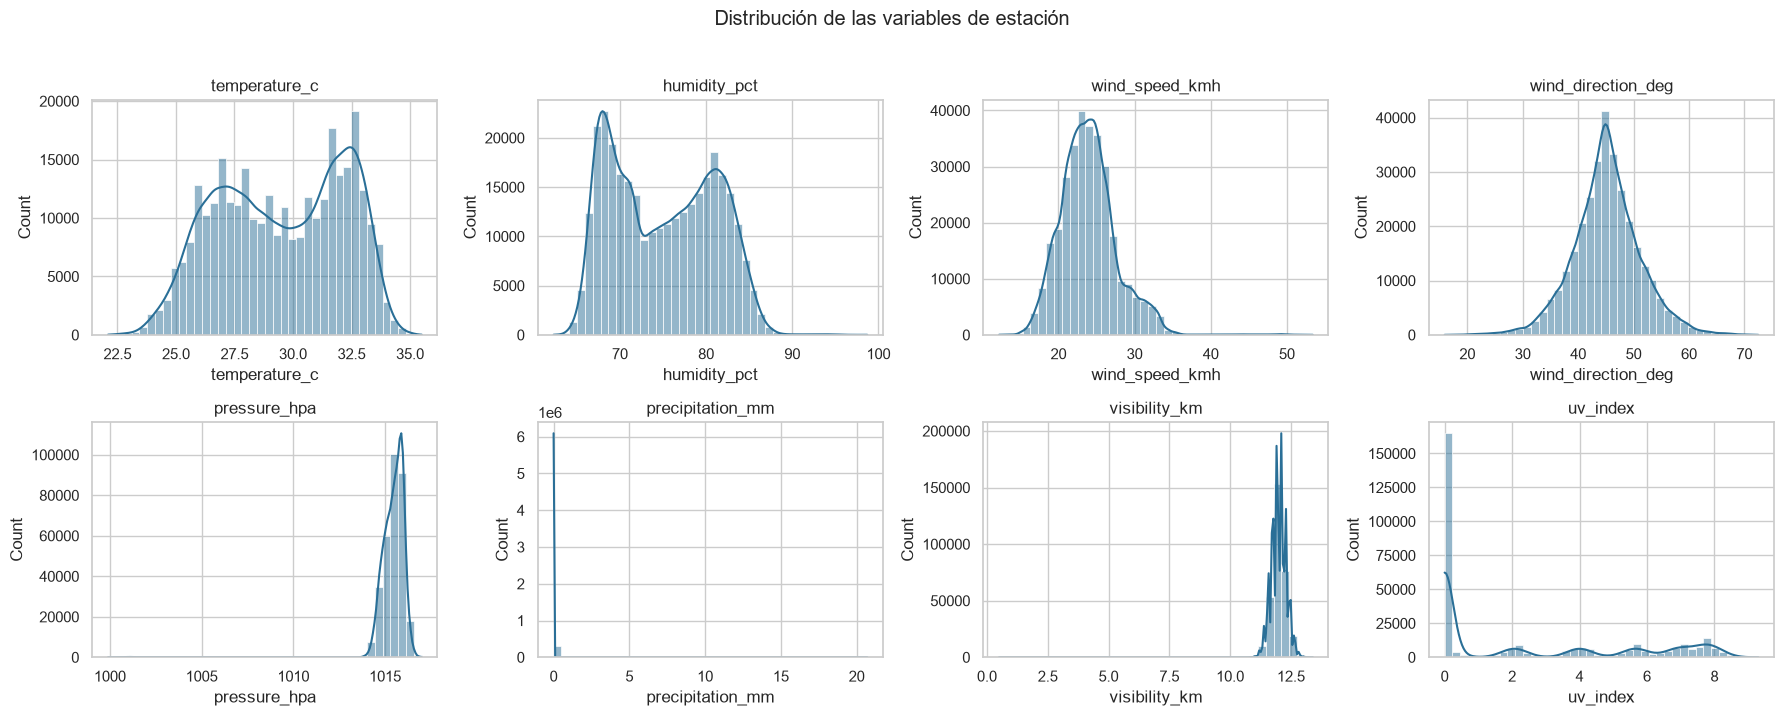

In [9]:
display(df[VARS].describe().T.round(2))
RANGOS = {"temperature_c": (15, 45), "humidity_pct": (0, 100), "wind_speed_kmh": (0, 150),
          "wind_direction_deg": (0, 360), "pressure_hpa": (980, 1040), "precipitation_mm": (0, 200),
          "visibility_km": (0, 50), "uv_index": (0, 16)}
print("Fuera de rango físico:", {v: int(((df[v] < lo) | (df[v] > hi)).sum()) for v, (lo, hi) in RANGOS.items()})
def n_iqr(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5*i) | (s > q3 + 1.5*i)).sum())
print("Outliers IQR:", {v: n_iqr(df[v].dropna()) for v in VARS})

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, v in zip(axes.ravel(), VARS):
    sns.histplot(df[v].dropna(), bins=40, kde=True, ax=ax, color="#2a6f97"); ax.set_title(v)
plt.suptitle("Distribución de las variables de estación", y=1.02); plt.tight_layout(); plt.show()

### 2.4 Correlaciones entre variables y entre estaciones

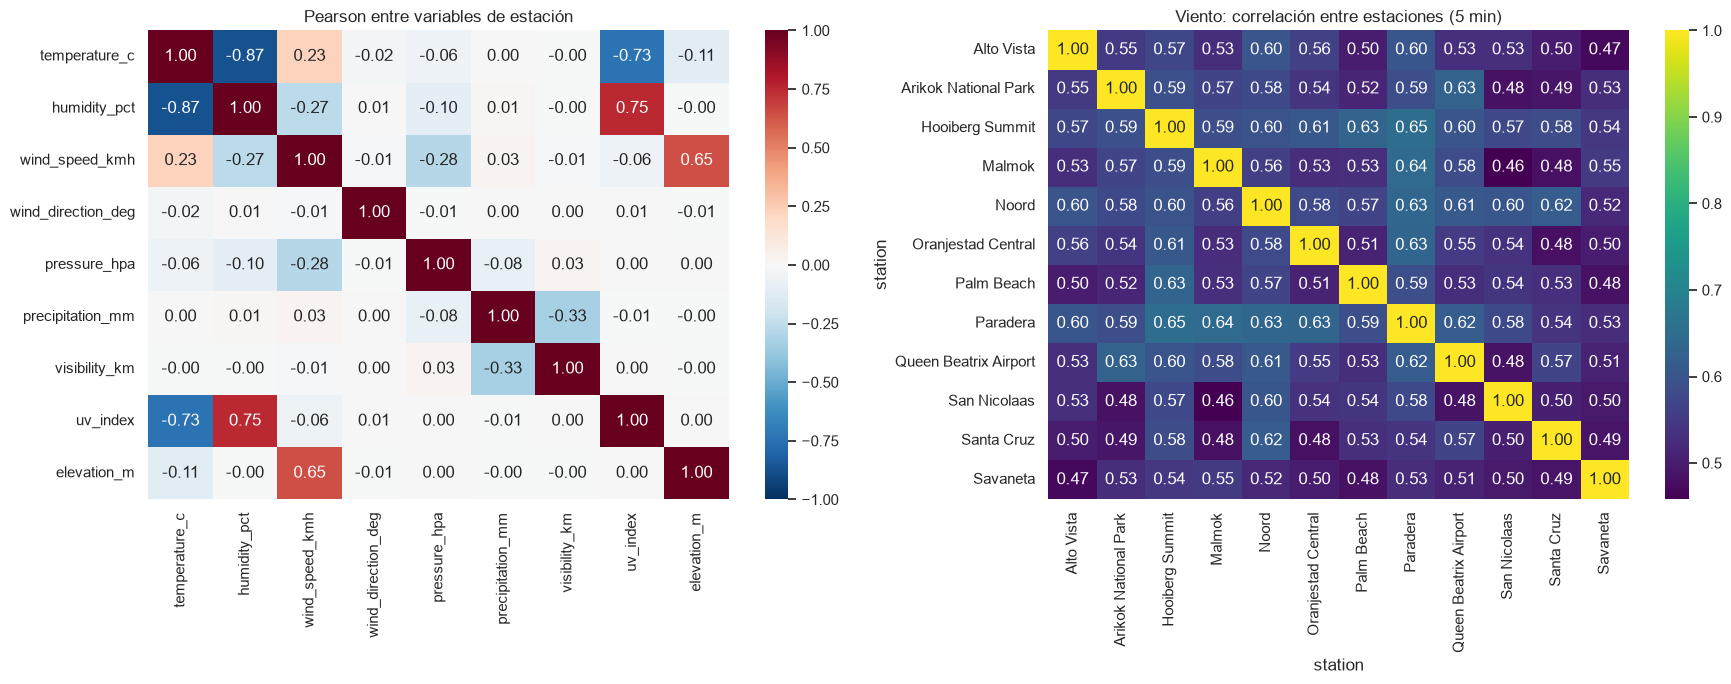

Correlación del viento entre pares de estaciones: media 0.55 | min 0.46 | max 0.65
Correlación de la temperatura entre pares de estaciones: media 0.88


Elevación vs viento medio: 1.0 | elevación vs temperatura: -0.96 | elevación vs presión: 0.12
(Físicamente esperado: presión ↓ ~0,12 hPa/m y temperatura ↓ ~0,0065 °C/m con la altura)


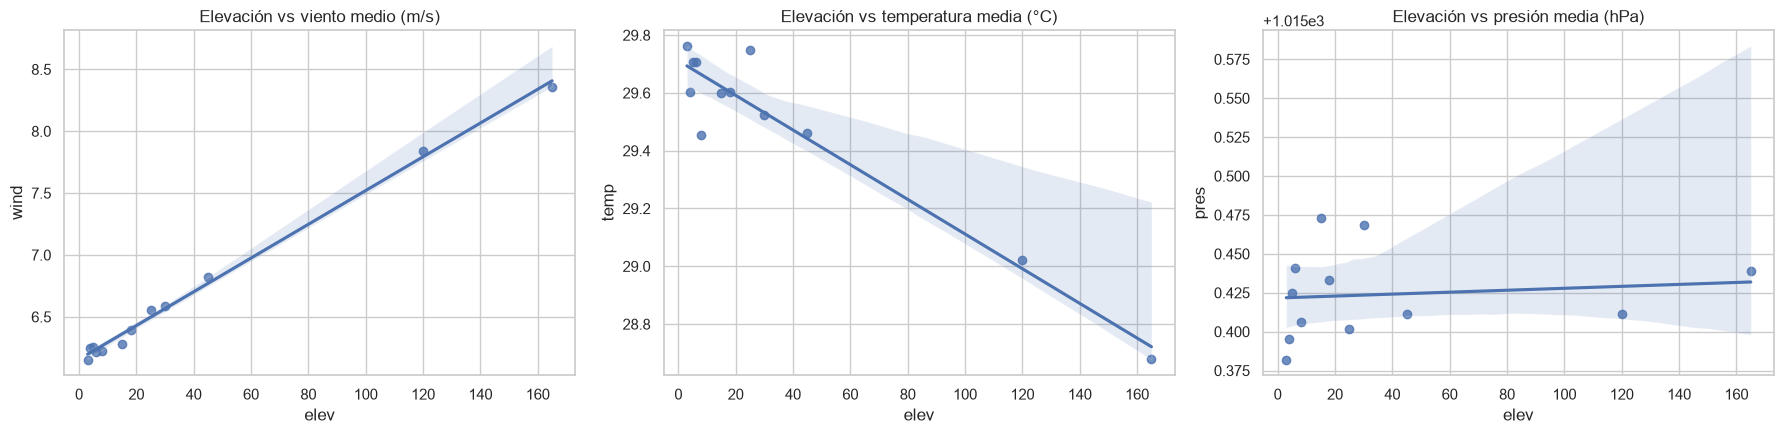

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(df[VARS + ["elevation_m"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Pearson entre variables de estación")
W = df.pivot_table(index="timestamp", columns="station", values="wind_ms")
sns.heatmap(W.corr(), annot=True, fmt=".2f", cmap="viridis", ax=ax[1]); ax[1].set_title("Viento: correlación entre estaciones (5 min)")
plt.tight_layout(); plt.show()
cw = W.corr().values[np.triu_indices(W.shape[1], 1)]
print(f"Correlación del viento entre pares de estaciones: media {cw.mean():.2f} | min {cw.min():.2f} | max {cw.max():.2f}")
Th = df.pivot_table(index="timestamp", columns="station", values="temperature_c").corr().values[np.triu_indices(W.shape[1], 1)]
print(f"Correlación de la temperatura entre pares de estaciones: media {Th.mean():.2f}")

est = df.groupby("station").agg(lat=("latitude", "first"), lon=("longitude", "first"), elev=("elevation_m", "first"),
                                wind=("wind_ms", "mean"), temp=("temperature_c", "mean"), pres=("pressure_hpa", "mean")).reset_index()
print("Elevación vs viento medio:", round(est.elev.corr(est.wind), 2),
      "| elevación vs temperatura:", round(est.elev.corr(est.temp), 2),
      "| elevación vs presión:", round(est.elev.corr(est.pres), 2))
print("(Físicamente esperado: presión ↓ ~0,12 hPa/m y temperatura ↓ ~0,0065 °C/m con la altura)")
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, v, t in zip(ax, ["wind", "temp", "pres"], ["viento medio (m/s)", "temperatura media (°C)", "presión media (hPa)"]):
    sns.regplot(data=est, x="elev", y=v, ax=a); a.set_title(f"Elevación vs {t}")
plt.tight_layout(); plt.show()

## 3. Reanálisis ERA5 (`datos_meteo.csv`)
Variables ERA5: `sp` presión superficial (Pa), `blh` altura de capa límite (m), `tcc` nubosidad total (0‑1), `u10/v10` y `u100/v100` viento (m/s),
`t2m` temperatura a 2 m (K), `fsr` rugosidad superficial (m), `ssrd` radiación solar descendente acumulada en 1 h (J/m²), `i10fg` racha a 10 m (m/s).
El fichero ya trae columnas derivadas: se **recalculan** para comprobar que son coherentes.

In [11]:
era = pd.read_csv(PATH_METEO, parse_dates=["time"])
era["time"] = era["time"].dt.tz_localize("UTC")
print("Forma:", era.shape, "| periodo:", era.time.min(), "→", era.time.max())
pts = era[["latitude", "longitude"]].drop_duplicates()
print("Puntos de rejilla:", len(pts))
pasos = era.time.drop_duplicates().sort_values().diff().value_counts()
print("Paso temporal:", pasos.to_dict())
print("Filas por punto:", era.groupby(["latitude", "longitude"]).size().unique())
print("Duplicados (time, lat, lon):", era.duplicated(["time", "latitude", "longitude"]).sum())
display(era.isna().mean().mul(100).round(2).to_frame("% nulos").T)
display(era.describe().T.round(3))

Forma: (62109, 20) | periodo: 2026-01-01 00:00:00+00:00 → 2026-10-15 12:00:00+00:00
Puntos de rejilla: 9
Paso temporal: {Timedelta('0 days 01:00:00'): 6900}
Filas por punto: [6901]
Duplicados (time, lat, lon): 0


,time,latitude,longitude,sp,blh,tcc,u10,v10,t2m,fsr,u100,v100,ssrd,i10fg,vel_viento_10m,vel_viento_100m,dir_viento_100m,t2m_C,sp_hPa,ssrd_Wm2
% nulos,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.35,0.0,0.0,0.0,0.0,0.0,0.0,8.35


,count,mean,std,min,25%,50%,75%,max
latitude,62109.0,12.500,0.204,12.250,12.250,12.500,12.750,12.750
longitude,62109.0,-70.000,0.204,-70.250,-70.250,-70.000,-69.750,-69.750
sp,62109.0,101196.440,165.890,100592.830,101083.340,101199.055,101310.720,101804.700
blh,62109.0,845.066,142.439,149.018,757.054,849.601,941.327,1431.292
tcc,62109.0,0.505,0.367,0.000,0.158,0.433,0.918,1.000
u10,62109.0,-9.354,1.552,-13.494,-10.423,-9.562,-8.522,-2.217
v10,62109.0,-0.136,1.470,-5.758,-1.192,-0.116,0.946,5.229
t2m,62109.0,300.212,0.863,297.412,299.570,300.144,300.879,302.554
fsr,62109.0,0.000,0.000,0.000,0.000,0.000,0.000,0.001
u100,62109.0,-11.254,2.086,-17.328,-12.713,-11.500,-10.124,-2.633


In [12]:
# Coherencia de las columnas derivadas
deriv = pd.DataFrame({
    "vel_viento_10m = |u10,v10|":   (era.vel_viento_10m - np.hypot(era.u10, era.v10)).abs(),
    "vel_viento_100m = |u100,v100|": (era.vel_viento_100m - np.hypot(era.u100, era.v100)).abs(),
    "dir_viento_100m (de dónde viene)": (((era.dir_viento_100m - (270 - np.degrees(np.arctan2(era.v100, era.u100))) % 360) + 180) % 360 - 180).abs(),
    "t2m_C = t2m - 273.15": (era.t2m_C - (era.t2m - 273.15)).abs(),
    "sp_hPa = sp / 100": (era.sp_hPa - era.sp / 100).abs(),
    "ssrd_Wm2 = ssrd / 3600": (era.ssrd_Wm2 - era.ssrd / 3600).abs(),
})
display(deriv.agg(["max", "mean"]).T.round(5))
print("Rachas ≥ viento medio a 10 m:", f"{(era.i10fg >= era.vel_viento_10m).mean():.1%}")
print("Viento 100 m ≥ viento 10 m:", f"{(era.vel_viento_100m >= era.vel_viento_10m).mean():.1%}")

# Exponente de cizalladura (ley potencial) entre 10 y 100 m
era["alpha"] = np.log(era.vel_viento_100m / era.vel_viento_10m) / np.log(100 / 10)
print("Exponente de cizalladura α (10→100 m): mediana", round(era.alpha.median(), 3), "| P10–P90",
      era.alpha.quantile([.1, .9]).round(3).tolist(), "(valor teórico 1/7 = 0.143)")
display(era.groupby(["latitude", "longitude"]).agg(ws100=("vel_viento_100m", "mean"), ws10=("vel_viento_10m", "mean"),
        alpha=("alpha", "median"), fsr=("fsr", "median"), ssrd=("ssrd_Wm2", "mean")).round(3))

,max,mean
"vel_viento_10m = |u10,v10|",0.00000,0.00000
"vel_viento_100m = |u100,v100|",0.00000,0.00000
dir_viento_100m (de dónde viene),0.00004,0.00001
t2m_C = t2m - 273.15,0.00002,0.00001
sp_hPa = sp / 100,0.00007,0.00002
ssrd_Wm2 = ssrd / 3600,0.00002,0.00000


Rachas ≥ viento medio a 10 m: 100.0%
Viento 100 m ≥ viento 10 m: 100.0%
Exponente de cizalladura α (10→100 m): mediana 0.077 | P10–P90 [0.055, 0.105] (valor teórico 1/7 = 0.143)


ws100   ws10  alpha  fsr   ssrd
latitude longitude                                  
12.25    -70.25     11.951  9.566  0.098  0.0  4.253
         -70.00     11.627  9.407  0.089  0.0  4.098
         -69.75     11.201  9.462  0.070  0.0  3.919
12.50    -70.25     11.640  9.520  0.088  0.0  4.078
         -70.00     11.378  9.493  0.076  0.0  3.950
         -69.75     11.044  9.330  0.070  0.0  3.803
12.75    -70.25     11.418  9.544  0.076  0.0  3.917
         -70.00     11.262  9.552  0.069  0.0  3.845
         -69.75     11.050  9.412  0.068  0.0  3.769

### 3.1 Coherencia física de la radiación `ssrd`
En Aruba (≈ 70° O) el mediodía solar es ≈ 16:40 UTC, el orto ≈ 10:30 UTC y el ocaso ≈ 23:00 UTC. La radiación tiene que ser **≥ 0**,
nula de noche y máxima hacia las 16‑17 UTC. Se compara con la elevación solar teórica.

time,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
ssrd_Wm2,-45.33,-0.05,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,11.26,116.84,198.12,202.76,175.76,123.90,57.05,-9.07,NaN,-146.90,-196.04,-218.70,-182.79
ssrd_min,-92.94,-0.66,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,0.00,8.23,37.69,-7.73,-130.52,-104.64,-155.82,-363.73,NaN,-278.47,-357.51,-270.15,-221.76
nulos,0.00,0.00,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.0,0.00,0.00,0.00,0.00
sol,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.10,0.33,0.55,0.73,0.87,0.94,0.96,0.91,0.8,0.63,0.43,0.20,0.00


Valores negativos de ssrd: 24.8% | horas siempre vacías (UTC): [7, 19]
Media de ssrd: 4.0 W/m² (esperable en Aruba ≈ 230–260 W/m²)
Correlación ssrd vs elevación solar (sin(elev)⁺): 0.39


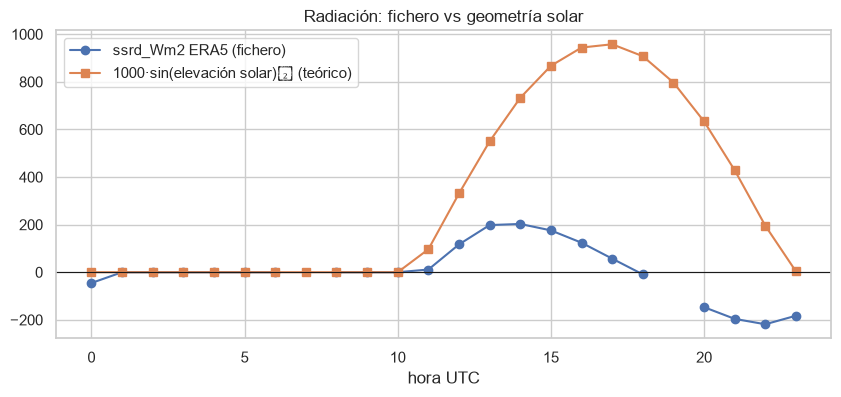

In [13]:
def seno_elevacion_solar(t_utc, lat=12.5, lon=-70.0):
    # Seno de la elevación solar (fórmula astronómica simplificada, error < 1°)
    doy = t_utc.dt.dayofyear.values; h = (t_utc.dt.hour + t_utc.dt.minute / 60).values
    g = 2 * np.pi / 365 * (doy - 1 + (h - 12) / 24)
    dec = 0.006918 - 0.399912*np.cos(g) + 0.070257*np.sin(g) - 0.006758*np.cos(2*g) + 0.000907*np.sin(2*g)
    eot = 229.18 * (0.000075 + 0.001868*np.cos(g) - 0.032077*np.sin(g) - 0.014615*np.cos(2*g) - 0.040849*np.sin(2*g))
    H = np.radians(15 * (h + lon / 15 + eot / 60 - 12))
    phi = np.radians(lat)
    return np.sin(phi)*np.sin(dec) + np.cos(phi)*np.cos(dec)*np.cos(H)

era["sin_elev"] = seno_elevacion_solar(era.time)
cic = era.groupby(era.time.dt.hour).agg(ssrd_Wm2=("ssrd_Wm2", "mean"), ssrd_min=("ssrd_Wm2", "min"),
                                        nulos=("ssrd_Wm2", lambda s: s.isna().mean()), sol=("sin_elev", lambda s: (s.clip(0)).mean()))
display(cic.round(2).T)
print(f"Valores negativos de ssrd: {(era.ssrd_Wm2 < 0).mean():.1%} | horas siempre vacías (UTC): {cic.index[cic.nulos == 1].tolist()}")
print(f"Media de ssrd: {era.ssrd_Wm2.mean():.1f} W/m² (esperable en Aruba ≈ 230–260 W/m²)")
print(f"Correlación ssrd vs elevación solar (sin(elev)⁺): {era.ssrd_Wm2.corr(era.sin_elev.clip(0)):.2f}")
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(cic.index, cic.ssrd_Wm2, marker="o", label="ssrd_Wm2 ERA5 (fichero)")
ax.plot(cic.index, cic.sol * 1000, marker="s", label="1000·sin(elevación solar)⁺ (teórico)")
ax.axhline(0, c="k", lw=.8); ax.set_xlabel("hora UTC"); ax.set_title("Radiación: fichero vs geometría solar"); ax.legend()
plt.show()

> **Resultado:** `ssrd` **no es coherente**. Hay valores negativos, las horas 07 y 19 UTC están vacías (son los reinicios de acumulación
> de ERA5 a las 06/18 UTC) y el máximo aparece a las 13‑14 UTC, unas 3 h antes del mediodía solar. La serie se ha desacumulado mal
> al descargarla. **No se usa `ssrd_Wm2` en este EDA.** Hay que volver a descargar la radiación (ERA5 `ssrd` en GRIB/netCDF desacumulando
> por pasos de previsión, u Open‑Meteo `shortwave_radiation`) o reconstruirla en `scripts/download_external_data.py`.

In [14]:
era.loc[:, "ssrd_Wm2"] = np.nan   # se invalida para el resto del análisis

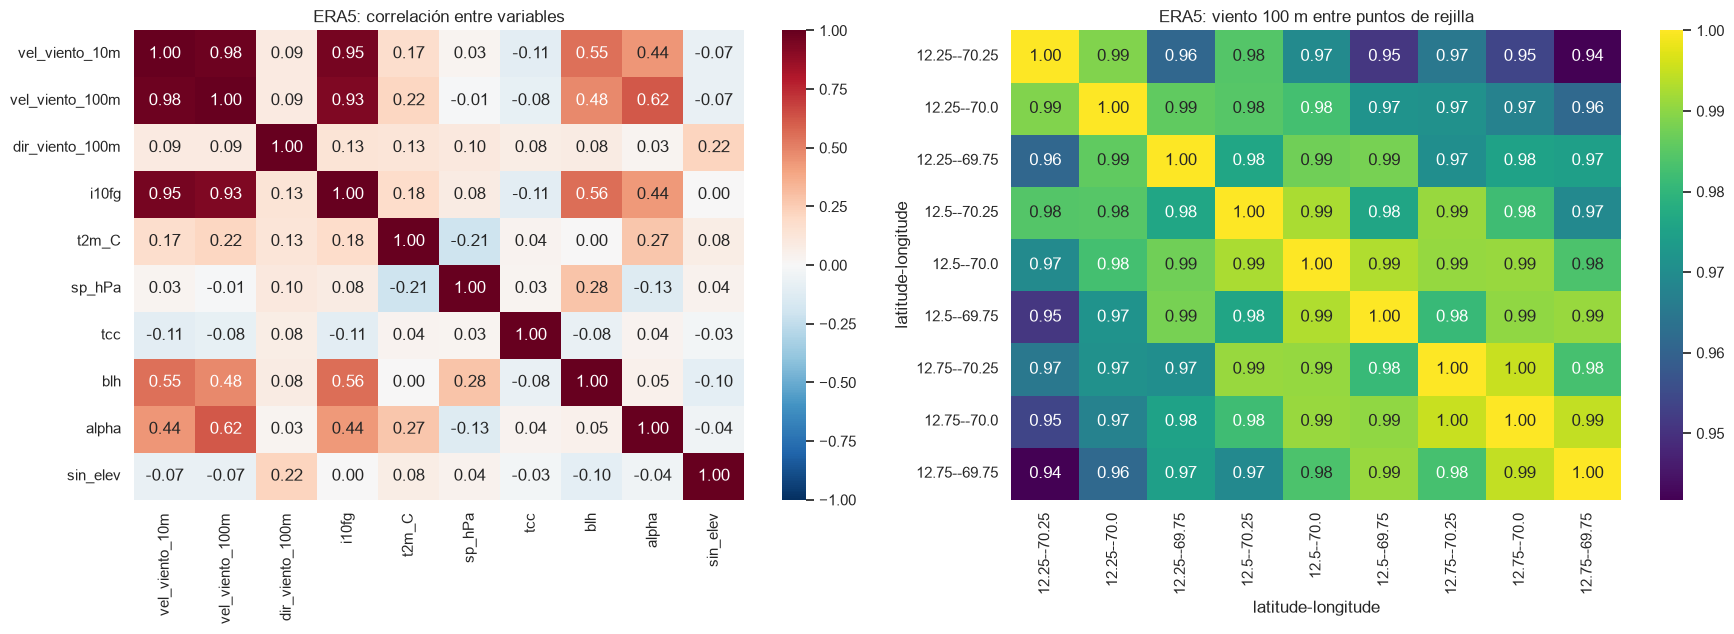

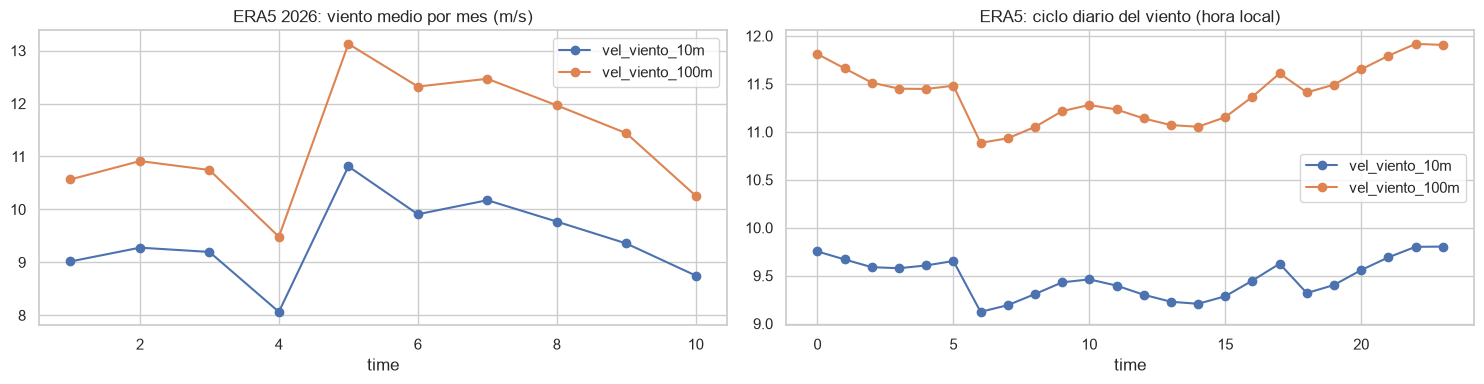

In [15]:
ERA_VARS = ["vel_viento_10m", "vel_viento_100m", "dir_viento_100m", "i10fg", "t2m_C", "sp_hPa", "tcc", "blh", "alpha", "sin_elev"]
fig, ax = plt.subplots(1, 2, figsize=(18, 6.5))
sns.heatmap(era[ERA_VARS].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("ERA5: correlación entre variables")
P = era.pivot_table(index="time", columns=["latitude", "longitude"], values="vel_viento_100m")
sns.heatmap(P.corr(), annot=True, fmt=".2f", cmap="viridis", ax=ax[1]); ax[1].set_title("ERA5: viento 100 m entre puntos de rejilla")
plt.tight_layout(); plt.show()
m = era.groupby(era.time.dt.month)[["vel_viento_10m", "vel_viento_100m"]].mean()
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
m[["vel_viento_10m", "vel_viento_100m"]].plot(ax=ax[0], marker="o"); ax[0].set_title("ERA5 2026: viento medio por mes (m/s)")
era.groupby(era.time.dt.tz_convert(TZ_LOCAL).dt.hour)[["vel_viento_10m", "vel_viento_100m"]].mean().plot(ax=ax[1], marker="o")
ax[1].set_title("ERA5: ciclo diario del viento (hora local)")
plt.tight_layout(); plt.show()

## 4. Coherencia estaciones ↔ ERA5
Se comparan en el **periodo común** y a **paso horario**. Las estaciones se asocian al punto de rejilla más cercano.
Ahora `datos_meteo.csv` incluye viento a **10 m**, así que la comparación de viento es a la misma altura (antes solo había 100 m).

In [16]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0; p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2-p1)/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(np.radians(lon2-lon1)/2)**2
    return 2*R*np.arcsin(np.sqrt(a))

grid = pts.reset_index(drop=True)
idx = [haversine(r.lat, r.lon, grid.latitude.values, grid.longitude.values).argmin() for r in est.itertuples()]
est["grid_lat"], est["grid_lon"] = grid.latitude.values[idx], grid.longitude.values[idx]
est["dist_km"] = haversine(est.lat, est.lon, est.grid_lat, est.grid_lon)
display(est[["station", "lat", "lon", "elev", "grid_lat", "grid_lon", "dist_km"]].round(3))

com0, com1 = max(T0, era.time.min()), min(T1, era.time.max())
print(f"Periodo común estaciones–ERA5: {com0} → {com1} ({(com1-com0).days} días)")

sh = (df.assign(t=df.timestamp.dt.floor("1h"))
        .groupby(["station", "t"])[["wind_ms", "wind_direction_deg", "temperature_c", "pressure_hpa", "humidity_pct", "uv_index", "visibility_km", "precipitation_mm"]]
        .mean().reset_index()
        .merge(est[["station", "elev", "grid_lat", "grid_lon"]], on="station"))
merged = sh.merge(era.rename(columns={"time": "t", "latitude": "grid_lat", "longitude": "grid_lon"}),
                  on=["t", "grid_lat", "grid_lon"], how="inner")
# dirección a 10 m desde u10/v10
merged["dir10"] = (270 - np.degrees(np.arctan2(merged.v10, merged.u10))) % 360
# elevación solar teórica en la estación (sustituye a ssrd, que no es fiable)
merged["sin_elev"] = seno_elevacion_solar(merged.t + pd.Timedelta(minutes=30))
print("Filas integradas (estación-hora):", merged.shape)

,station,lat,lon,elev,grid_lat,grid_lon,dist_km
0,Alto Vista,12.591,-70.037,25,12.5,-70.0,10.923
1,Arikok National Park,12.501,-69.954,120,12.5,-70.0,5.016
2,Hooiberg Summit,12.520,-69.999,165,12.5,-70.0,2.270
3,Malmok,12.596,-70.049,6,12.5,-70.0,11.931
4,Noord,12.564,-70.032,15,12.5,-70.0,7.964
5,Oranjestad Central,12.520,-70.037,5,12.5,-70.0,4.606
6,Palm Beach,12.563,-70.042,3,12.5,-70.0,8.303
7,Paradera,12.535,-70.005,30,12.5,-70.0,3.974
8,Queen Beatrix Airport,12.504,-70.003,18,12.5,-70.0,0.576
9,San Nicolaas,12.436,-69.909,8,12.5,-70.0,12.150


Periodo común estaciones–ERA5: 2026-03-31 22:00:00+00:00 → 2026-06-30 21:35:00+00:00 (90 días)
Filas integradas (estación-hora): (26208, 33)


In [17]:
PARES = [("wind_ms", "vel_viento_10m", "Viento 10 m (m/s)"), ("wind_ms", "vel_viento_100m", "Viento est. vs ERA5 100 m"),
         ("temperature_c", "t2m_C", "Temperatura (°C)"), ("pressure_hpa", "sp_hPa", "Presión (hPa)"),
         ("uv_index", "sin_elev", "UV vs elevación solar"), ("humidity_pct", "tcc", "Humedad vs nubosidad"),
         ("visibility_km", "tcc", "Visibilidad vs nubosidad")]
def resumen_par(g, a, b):
    return pd.Series({"pearson": g[a].corr(g[b]), "spearman": g[a].corr(g[b], method="spearman"),
                      "media_est": g[a].mean(), "media_era5": g[b].mean(), "sesgo (est-ERA5)": (g[a] - g[b]).mean()})
tabla = pd.DataFrame({t: resumen_par(merged, a, b) for a, b, t in PARES}).T
display(tabla.round(3))

d = ((merged.wind_direction_deg - merged.dir10 + 180) % 360) - 180
print(f"Dirección media: estación {merged.wind_direction_deg.mean():.0f}° (NE) vs ERA5 10 m {merged.dir10.mean():.0f}° (E) | "
      f"dif. mediana {d.median():.1f}° | desviación típica: estación {merged.wind_direction_deg.std():.1f}° vs ERA5 {merged.dir10.std():.1f}°")

porest = merged.groupby("station").apply(lambda g: pd.Series({
    "elev": g.elev.iloc[0], "r_viento10": g.wind_ms.corr(g.vel_viento_10m), "ratio_viento est/ERA5": g.wind_ms.mean() / g.vel_viento_10m.mean(),
    "r_temp": g.temperature_c.corr(g.t2m_C), "sesgo_temp": (g.temperature_c - g.t2m_C).mean(),
    "presion_media": g.pressure_hpa.mean(), "sesgo_pres": (g.pressure_hpa - g.sp_hPa).mean()})).sort_values("elev")
display(porest.round(3))
print("Una estación a 165 m debería medir ~20 hPa menos que una a nivel del mar; aquí la diferencia es "
      f"{porest.presion_media.iloc[-1] - porest.presion_media.iloc[0]:+.2f} hPa → la presión de estación parece reducida a nivel del mar (o sintética).")

# Variabilidad día a día (escala sinóptica)
dia_est = df.set_index("timestamp").wind_ms.resample("1D").mean()
dia_era = era[(era.latitude == 12.5) & (era.longitude == -70.0)].set_index("time").vel_viento_10m.resample("1D").mean()
print(f"Desv. típica del viento medio diario: estaciones {dia_est.std():.2f} m/s vs ERA5 {dia_era[dia_est.index.min():dia_est.index.max()].std():.2f} m/s")
print(f"Correlación elevación–viento medio entre estaciones: {est.elev.corr(est.wind):.3f} (relación casi determinista)")

,pearson,spearman,media_est,media_era5,sesgo (est-ERA5)
Viento 10 m (m/s),0.079,0.093,6.661,9.587,-2.926
Viento est. vs ERA5 100 m,0.058,0.071,6.661,11.626,-4.965
Temperatura (°C),0.230,0.225,29.490,26.810,2.679
Presión (hPa),-0.221,-0.384,1015.424,1011.846,3.578
UV vs elevación solar,0.426,0.435,2.542,0.063,2.478
Humedad vs nubosidad,0.045,0.044,75.013,0.567,74.446
Visibilidad vs nubosidad,-0.012,-0.011,11.996,0.567,11.430


Dirección media: estación 45° (NE) vs ERA5 10 m 90° (E) | dif. mediana -45.1° | desviación típica: estación 6.0° vs ERA5 8.8°


,elev,r_viento10,ratio_viento est/ERA5,r_temp,sesgo_temp,presion_media,sesgo_pres
station,,,,,,,
Palm Beach,3.0,0.104,0.642,0.205,2.951,1015.382,3.536
Savaneta,4.0,0.023,0.652,0.194,2.794,1015.395,3.549
Oranjestad Central,5.0,0.173,0.653,0.200,2.898,1015.424,3.579
Malmok,6.0,0.093,0.648,0.223,2.895,1015.441,3.595
San Nicolaas,8.0,0.123,0.649,0.201,2.646,1015.406,3.561
Noord,15.0,0.151,0.655,0.246,2.788,1015.473,3.627
Queen Beatrix Airport,18.0,0.122,0.667,0.290,2.794,1015.433,3.587
Alto Vista,25.0,0.064,0.683,0.270,2.939,1015.401,3.556
Paradera,30.0,0.118,0.687,0.229,2.713,1015.468,3.623


Una estación a 165 m debería medir ~20 hPa menos que una a nivel del mar; aquí la diferencia es +0.06 hPa → la presión de estación parece reducida a nivel del mar (o sintética).
Desv. típica del viento medio diario: estaciones 0.10 m/s vs ERA5 1.58 m/s
Correlación elevación–viento medio entre estaciones: 0.998 (relación casi determinista)


### 4.1 Desfase temporal (¿están en UTC las marcas de tiempo?)
La prueba más fiable es la **geometría solar**: el UV tiene que seguir a la elevación del sol. Si las marcas de tiempo de las estaciones
estuvieran en hora local (UTC‑4) etiquetadas como `Z`, la mejor correlación aparecería al desplazarlas unas 4 h. La misma prueba se aplica a la
temperatura, que en tierra alcanza el máximo entre 1 y 3 h después del mediodía solar.

r(UV, sol): r máx = 0.992 sumando +4.0 h al timestamp (r sin desplazar = 0.305)
r(T, sol con 2 h de retraso): r máx = 0.987 sumando -7.5 h al timestamp (r sin desplazar = -0.431)
Hora UTC del máximo: UV 12 | temperatura 2 | mínimo de temperatura 14 | (mediodía solar real ≈ 16-17 UTC)
UV > 0 entre 6 y 18 UTC (sol real sobre el horizonte ≈ 10:30–23:00 UTC)


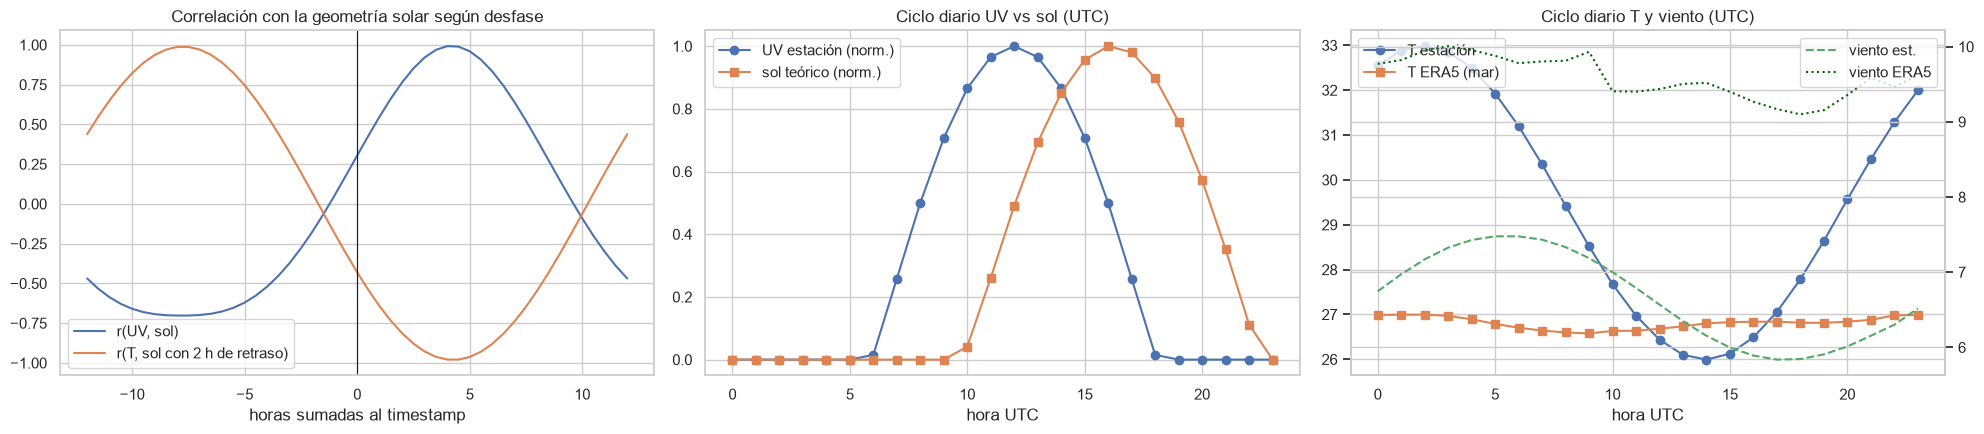

In [18]:
uv5 = df.groupby("timestamp")[["uv_index", "temperature_c", "wind_ms"]].mean()
def sol(desfase_h, retraso_h=0.0):
    t = (uv5.index + pd.Timedelta(hours=desfase_h - retraso_h)).to_series()
    return pd.Series(seno_elevacion_solar(t), index=uv5.index)
DESF = np.arange(-12, 12.5, 0.5)
res = pd.DataFrame({"r(UV, sol)": [uv5.uv_index.corr(sol(h).clip(0)) for h in DESF],
                    "r(T, sol con 2 h de retraso)": [uv5.temperature_c.corr(sol(h, 2)) for h in DESF]}, index=DESF)
res.index.name = "horas sumadas al timestamp"
for c in res:
    print(f"{c}: r máx = {res[c].max():.3f} sumando {res[c].idxmax():+.1f} h al timestamp (r sin desplazar = {res.loc[0.0, c]:.3f})")

h_utc = uv5.groupby(uv5.index.hour).mean()
print("Hora UTC del máximo: UV", int(h_utc.uv_index.idxmax()), "| temperatura", int(h_utc.temperature_c.idxmax()),
      "| mínimo de temperatura", int(h_utc.temperature_c.idxmin()), "| (mediodía solar real ≈ 16-17 UTC)")
print("UV > 0 entre", int(h_utc.index[h_utc.uv_index > 0.05].min()), "y", int(h_utc.index[h_utc.uv_index > 0.05].max()),
      "UTC (sol real sobre el horizonte ≈ 10:30–23:00 UTC)")

fig, ax = plt.subplots(1, 3, figsize=(20, 4.5))
res.plot(ax=ax[0]); ax[0].axvline(0, c="k", lw=.8); ax[0].set_title("Correlación con la geometría solar según desfase")
sol_h = sol(0).clip(0).groupby(uv5.index.hour).mean()
ax[1].plot(h_utc.index, h_utc.uv_index / h_utc.uv_index.max(), marker="o", label="UV estación (norm.)")
ax[1].plot(sol_h.index, sol_h / sol_h.max(), marker="s", label="sol teórico (norm.)")
ax[1].set_xlabel("hora UTC"); ax[1].legend(); ax[1].set_title("Ciclo diario UV vs sol (UTC)")
ce = era[(era.latitude == 12.5) & (era.longitude == -70.0) & (era.time >= T0) & (era.time <= T1)]
ce = ce.groupby(ce.time.dt.hour)[["t2m_C", "vel_viento_10m"]].mean()
ax[2].plot(h_utc.index, h_utc.temperature_c, marker="o", label="T estación")
ax[2].plot(ce.index, ce.t2m_C, marker="s", label="T ERA5 (mar)")
ax3 = ax[2].twinx(); ax3.plot(h_utc.index, h_utc.wind_ms, c="g", ls="--", label="viento est."); ax3.plot(ce.index, ce.vel_viento_10m, c="darkgreen", ls=":", label="viento ERA5")
ax[2].set_xlabel("hora UTC"); ax[2].legend(loc="upper left"); ax3.legend(loc="upper right"); ax[2].set_title("Ciclo diario T y viento (UTC)")
plt.tight_layout(); plt.show()

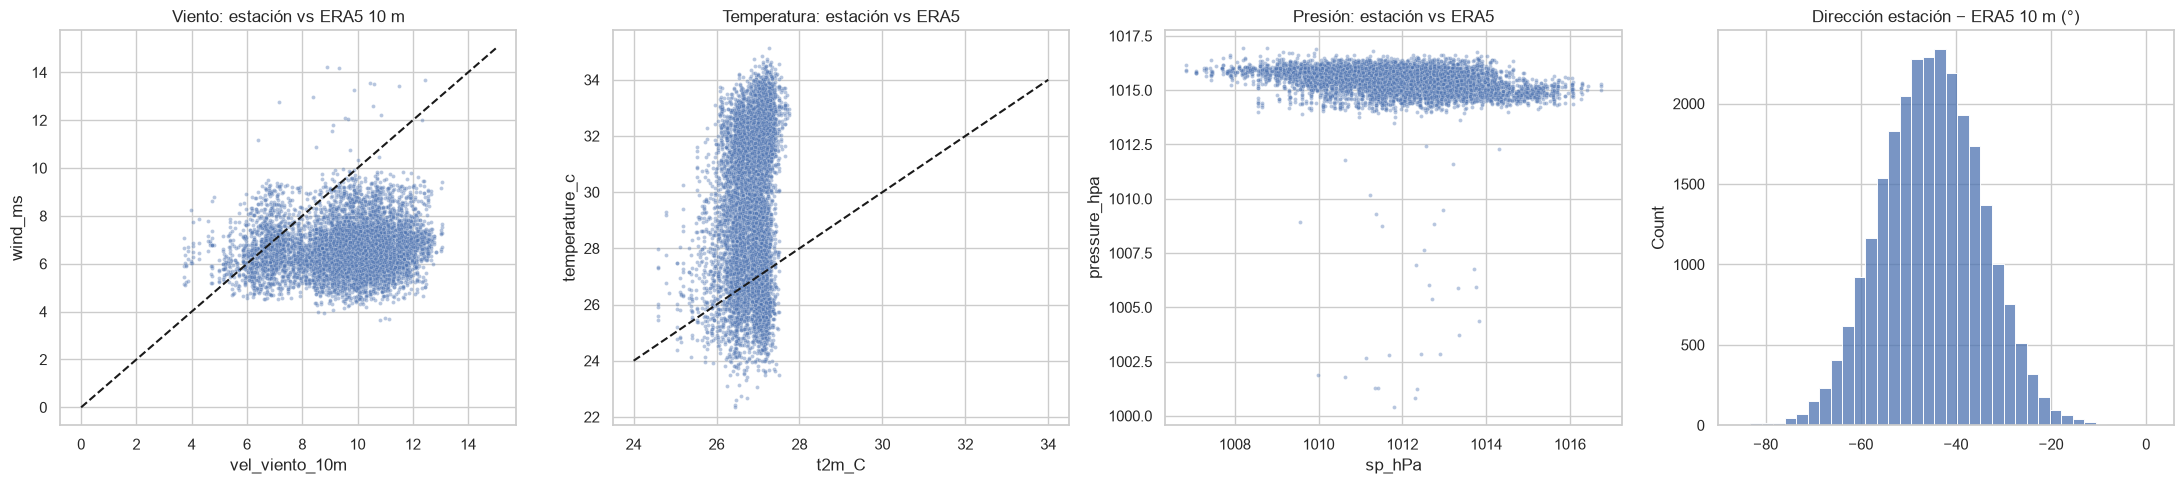

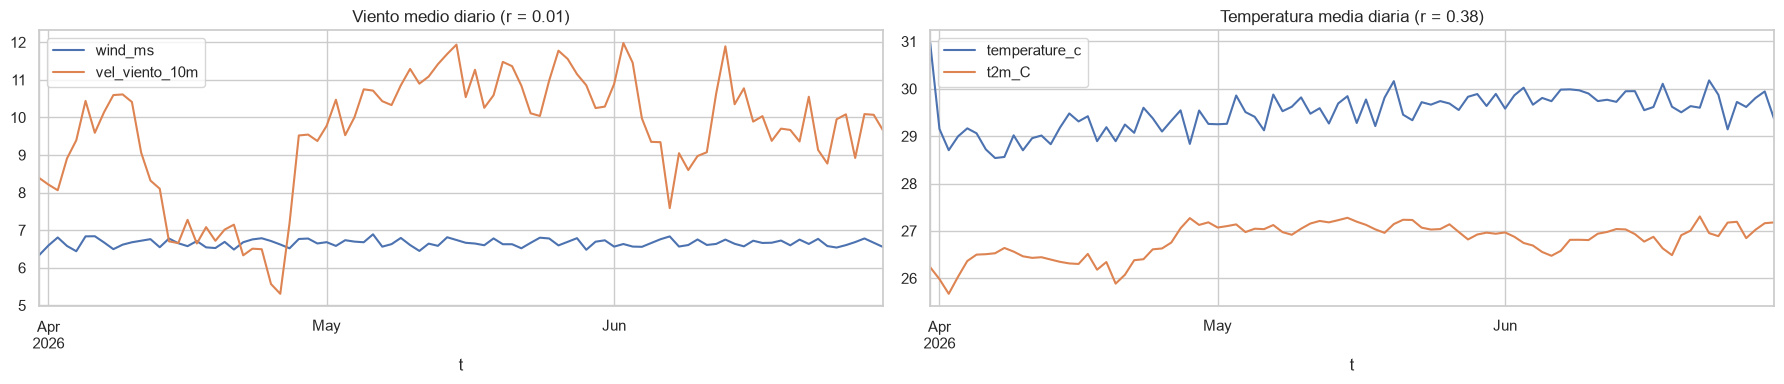

In [19]:
s = merged.sample(min(len(merged), 8000), random_state=0)
fig, ax = plt.subplots(1, 4, figsize=(22, 5))
sns.scatterplot(data=s, x="vel_viento_10m", y="wind_ms", s=8, alpha=.4, ax=ax[0]); ax[0].plot([0, 15], [0, 15], "k--"); ax[0].set_title("Viento: estación vs ERA5 10 m")
sns.scatterplot(data=s, x="t2m_C", y="temperature_c", s=8, alpha=.4, ax=ax[1]); ax[1].plot([24, 34], [24, 34], "k--"); ax[1].set_title("Temperatura: estación vs ERA5")
sns.scatterplot(data=s, x="sp_hPa", y="pressure_hpa", s=8, alpha=.4, ax=ax[2]); ax[2].set_title("Presión: estación vs ERA5")
sns.histplot(d, bins=36, ax=ax[3]); ax[3].set_title("Dirección estación − ERA5 10 m (°)")
plt.tight_layout(); plt.show()

prom = merged.groupby("t")[["wind_ms", "vel_viento_10m", "temperature_c", "t2m_C"]].mean()
dia = prom.resample("1D").mean()
fig, ax = plt.subplots(1, 2, figsize=(18, 4))
dia[["wind_ms", "vel_viento_10m"]].plot(ax=ax[0]); ax[0].set_title(f"Viento medio diario (r = {dia.wind_ms.corr(dia.vel_viento_10m):.2f})")
dia[["temperature_c", "t2m_C"]].plot(ax=ax[1]); ax[1].set_title(f"Temperatura media diaria (r = {dia.temperature_c.corr(dia.t2m_C):.2f})")
plt.tight_layout(); plt.show()

### 4.2 Correlaciones tras corregir el huso horario (+4 h)
Se repite la comparación con ERA5 suponiendo que el timestamp real es `timestamp + 4 h` (hora local de Aruba etiquetada como UTC).

In [20]:
CORR_TZ_H = 4
isla = df.groupby("timestamp")[["wind_ms", "temperature_c", "pressure_hpa", "uv_index", "humidity_pct"]].mean()
e0 = era[(era.latitude == 12.5) & (era.longitude == -70.0)].set_index("time")[["vel_viento_10m", "vel_viento_100m", "t2m_C", "sp_hPa", "tcc", "sin_elev"]]
filas = []
for etiqueta, h in [("sin corregir", 0), (f"+{CORR_TZ_H} h", CORR_TZ_H)]:
    x = isla.copy(); x.index = x.index + pd.Timedelta(hours=h)
    j = x.resample("1h").mean().join(e0, how="inner")
    filas.append(pd.Series({"viento est vs ERA5 10 m": j.wind_ms.corr(j.vel_viento_10m),
                            "temperatura est vs ERA5": j.temperature_c.corr(j.t2m_C),
                            "presión est vs ERA5": j.pressure_hpa.corr(j.sp_hPa),
                            "UV vs elevación solar": j.uv_index.corr(j.sin_elev.clip(0)),
                            "temperatura vs elevación solar": j.temperature_c.corr(j.sin_elev),
                            "humedad vs nubosidad": j.humidity_pct.corr(j.tcc)}, name=etiqueta))
display(pd.DataFrame(filas).T.round(3))

,sin corregir,+4 h
viento est vs ERA5 10 m,0.136,0.032
temperatura est vs ERA5,0.245,-0.032
presión est vs ERA5,-0.401,-0.406
UV vs elevación solar,0.191,0.976
temperatura vs elevación solar,-0.743,-0.926
humedad vs nubosidad,0.048,-0.064


### 4.3 Matriz de correlación conjunta (estaciones corregidas + ERA5 + sol)

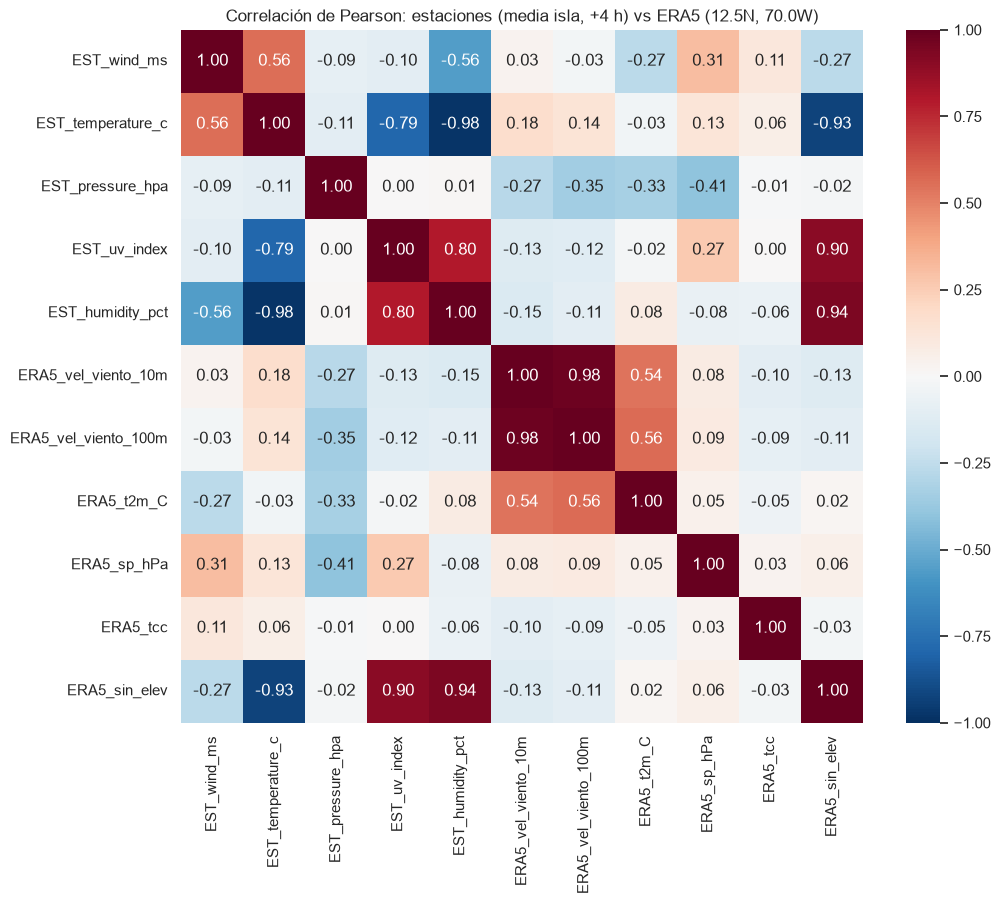

In [21]:
x = isla.copy(); x.index = x.index + pd.Timedelta(hours=CORR_TZ_H)
J = x.resample("1h").mean().join(e0, how="inner")
J.columns = [f"EST_{c}" if c in isla.columns else f"ERA5_{c}" for c in J.columns]
plt.figure(figsize=(11, 9))
sns.heatmap(J.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlación de Pearson: estaciones (media isla, +4 h) vs ERA5 (12.5N, 70.0W)"); plt.show()

## 5. Potencia del parque con la curva de la Vestas V90‑3.0
La ficha (`turbinas.json`) da arranque, nominal y corte, pero **no la curva punto a punto**. Se usa la curva publicada para la V90‑3.0
(densidad 1,225 kg/m³, valores aproximados) anclada a los parámetros de la ficha. El viento a buje (80 m) se obtiene de ERA5 100 m
con el α horario calculado entre 10 y 100 m.

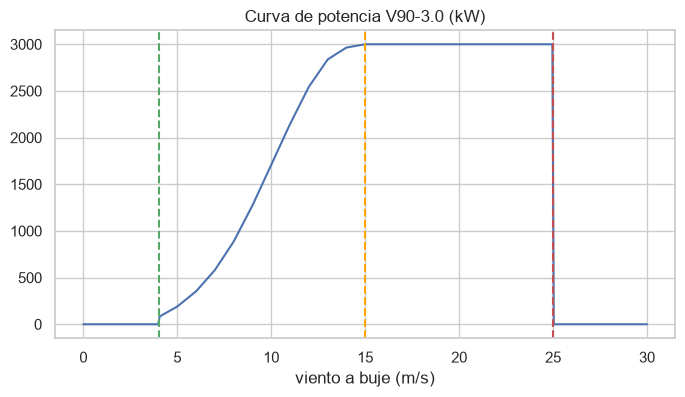

Punto ERA5 del parque: (12.5, -70.0), a 8.3 km
Viento medio a buje 11.18 m/s | % horas ≥ nominal: 0.8% | % horas < arranque: 0.0% | ≥ corte: 0.00%
Factor de capacidad estimado ERA5 (ene–oct 2026): 71.6%  vs histórico medio 53.0 % (2025: 53.0 %)
→ Factor de corrección implícito (pérdidas por estela, disponibilidad, curtailment…): 0.74


In [22]:
CURVA_WS = [0, V_ARRANQUE - 0.01, V_ARRANQUE, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, V_NOMINAL, V_CORTE, V_CORTE + 0.01, 40]
CURVA_KW = [0, 0, 77, 190, 353, 581, 886, 1273, 1710, 2145, 2544, 2837, 2965, P_NOMINAL_KW, P_NOMINAL_KW, 0, 0]
def potencia_turbina_kw(ws): return np.interp(ws, CURVA_WS, CURVA_KW)
def potencia_parque_kw(ws): return N_TURBINAS * potencia_turbina_kw(ws)

plt.figure(figsize=(8, 4)); x = np.linspace(0, 30, 400)
plt.plot(x, potencia_turbina_kw(x)); [plt.axvline(v, ls="--", c=c) for v, c in [(V_ARRANQUE, "g"), (V_NOMINAL, "orange"), (V_CORTE, "r")]]
plt.title("Curva de potencia V90-3.0 (kW)"); plt.xlabel("viento a buje (m/s)"); plt.show()

ip = haversine(*PARQUE_LATLON, grid.latitude.values, grid.longitude.values).argmin()
pq = era[(era.latitude == grid.latitude[ip]) & (era.longitude == grid.longitude[ip])].set_index("time").sort_index()
print(f"Punto ERA5 del parque: ({grid.latitude[ip]}, {grid.longitude[ip]}), a {haversine(*PARQUE_LATLON, grid.latitude[ip], grid.longitude[ip]):.1f} km")
alpha = pq.alpha.clip(0, 0.5)
pq["ws_buje"] = pq.vel_viento_100m * (ALTURA_BUJE_M / 100) ** alpha
pq["P_kw"] = potencia_parque_kw(pq.ws_buje)
cf_era = pq.P_kw.mean() / (CAP_EOLICA_MW * 1000)
print(f"Viento medio a buje {pq.ws_buje.mean():.2f} m/s | % horas ≥ nominal: {(pq.ws_buje >= V_NOMINAL).mean():.1%} | "
      f"% horas < arranque: {(pq.ws_buje < V_ARRANQUE).mean():.1%} | ≥ corte: {(pq.ws_buje >= V_CORTE).mean():.2%}")
print(f"Factor de capacidad estimado ERA5 (ene–oct 2026): {cf_era:.1%}  vs histórico medio {hist.capacity_percent.mean():.1f} % "
      f"(2025: {hist.capacity_percent.iloc[-1]:.1f} %)")
FACTOR_PERDIDAS = hist.capacity_percent.iloc[-1] / 100 / cf_era
print(f"→ Factor de corrección implícito (pérdidas por estela, disponibilidad, curtailment…): {FACTOR_PERDIDAS:.2f}")

Estaciones (media isla) a buje con α=0.077: viento medio 7.81 m/s | CF 28.4%
Correlación horaria potencia estaciones vs ERA5 (periodo común): 0.08


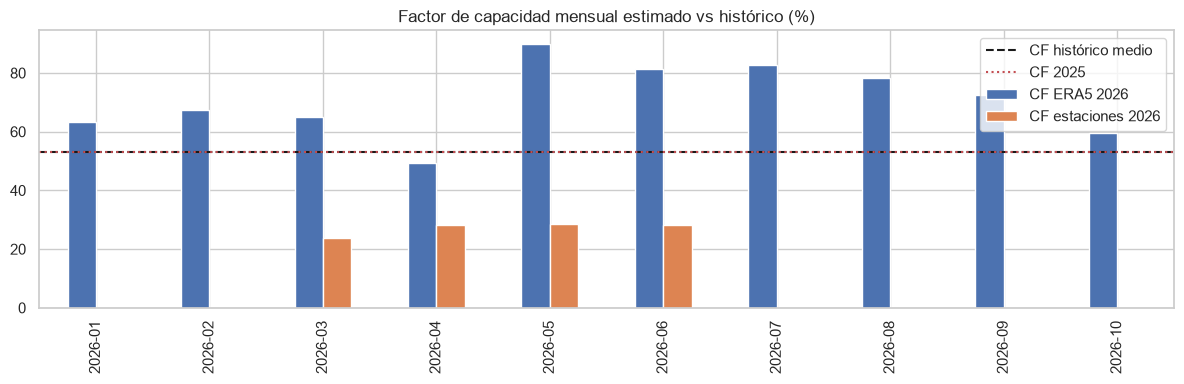

In [23]:
# Misma estimación con el viento de las estaciones (5 min) extrapolado a buje con el α de ERA5
alpha_med = float(era.alpha.median())
W5 = W.resample("5min").mean().interpolate(limit=3)
ratio_est = W5.mean() / W5.mean().mean()
v_est = W5.mean(axis=1) * (ALTURA_BUJE_M / ALTURA_ESTACION_M) ** alpha_med
P5 = pd.Series(potencia_parque_kw(v_est.values), index=v_est.index).where(v_est.notna())
print(f"Estaciones (media isla) a buje con α={alpha_med:.3f}: viento medio {v_est.mean():.2f} m/s | CF {P5.mean()/(CAP_EOLICA_MW*1000):.1%}")

comp = pd.DataFrame({"P_estaciones": P5.resample("1h").mean(), "P_era5": pq.P_kw}).dropna()
print(f"Correlación horaria potencia estaciones vs ERA5 (periodo común): {comp.corr().iloc[0, 1]:.2f}")

mes = pd.DataFrame({"CF ERA5 2026": pq.P_kw.resample("ME").mean() / (CAP_EOLICA_MW*1000) * 100,
                    "CF estaciones 2026": P5.resample("ME").mean() / (CAP_EOLICA_MW*1000) * 100})
mes.index = mes.index.strftime("%Y-%m")
ax = mes.plot(kind="bar", figsize=(12, 4)); ax.axhline(hist.capacity_percent.mean(), c="k", ls="--", label="CF histórico medio")
ax.axhline(hist.capacity_percent.iloc[-1], c="r", ls=":", label="CF 2025"); ax.legend(); ax.set_title("Factor de capacidad mensual estimado vs histórico (%)")
plt.tight_layout(); plt.show()

## 6. Umbrales y demanda (primera aproximación para RF-08)

In [24]:
P_real = pq.P_kw * FACTOR_PERDIDAS        # estimación calibrada al histórico
for nombre, serie in [("ERA5 curva pura", pq.P_kw), ("ERA5 calibrada al histórico", P_real), ("estaciones 5 min", P5.dropna())]:
    print(f"{nombre:28s} media {serie.mean():7.0f} kW | P15 {serie.quantile(.15):7.0f} kW | "
          f"% < {UMBRAL_ALERTA_KW} kW: {(serie < UMBRAL_ALERTA_KW).mean():5.1%} | % < 15% nominal: {(serie < 0.15*CAP_EOLICA_MW*1000).mean():5.1%}")

dem_media, dem_pico = dem["average_mw"], dem["max_peak_mw"]
cuota = P_real / 1000 / dem_media
print(f"\nCon la demanda media de {dem_media} MW, la eólica cubriría de media un {cuota.mean():.1%} (máx {cuota.max():.1%}).")
print(f"El déficit a cubrir por térmica/solar/baterías sería ≥ {dem_media - CAP_EOLICA_MW:.0f} MW incluso con el parque a plena carga.")
print(f"BESS: {equip['energy_storage']['bess_i']['power_mw']} MW / {equip['energy_storage']['bess_i']['capacity_mwh']} MWh "
      f"→ cubre {equip['energy_storage']['bess_i']['power_mw']/CAP_EOLICA_MW:.1%} de una caída total del parque durante "
      f"{equip['energy_storage']['bess_i']['capacity_mwh']/equip['energy_storage']['bess_i']['power_mw']:.0f} h")

ERA5 curva pura              media   21493 kW | P15   13709 kW | % < 500 kW:  0.0% | % < 15% nominal:  1.6%
ERA5 calibrada al histórico  media   15900 kW | P15   10141 kW | % < 500 kW:  0.0% | % < 15% nominal:  3.5%
estaciones 5 min             media    8510 kW | P15    5744 kW | % < 500 kW:  0.0% | % < 15% nominal:  0.1%

Con la demanda media de 121 MW, la eólica cubriría de media un 13.1% (máx 18.3%).
El déficit a cubrir por térmica/solar/baterías sería ≥ 91 MW incluso con el parque a plena carga.
BESS: 1 MW / 4 MWh → cubre 3.3% de una caída total del parque durante 4 h


## 7. Predictibilidad a 15 min (persistencia, línea base RF-10)

In [25]:
lags5 = [1, 2, 3, 4, 6, 12]
display(pd.Series({f"{5*l} min": P5.autocorr(l) for l in lags5}, name="autocorrelación potencia (estaciones)").round(3).to_frame())
y = P5.shift(-3); ok = y.notna() & P5.notna()
rmse = np.sqrt(((y[ok] - P5[ok]) ** 2).mean()); r2 = 1 - ((y[ok]-P5[ok])**2).sum() / ((y[ok]-y[ok].mean())**2).sum()
print(f"Persistencia t+15 min (estaciones, 5 min) → RMSE = {rmse:.1f} kW | R² = {r2:.3f}")
dP = (y - P5)[ok]
print(f"Cambios a 15 min: P95 |ΔP| = {dP.abs().quantile(.95):.0f} kW | caídas > 10% nominal: {(dP < -0.1*CAP_EOLICA_MW*1000).mean():.2%} de los instantes")

,autocorrelación potencia (estaciones)
5 min,0.999
10 min,0.998
15 min,0.997
20 min,0.995
30 min,0.989
60 min,0.959


Persistencia t+15 min (estaciones, 5 min) → RMSE = 190.1 kW | R² = 0.994
Cambios a 15 min: P95 |ΔP| = 324 kW | caídas > 10% nominal: 0.00% de los instantes


## 8. Conclusiones: coherencia entre fuentes

**Fuentes coherentes**
- `equipment_installed.json` es internamente consistente: las sumas térmica (252,4 MW) y renovable (36,1 MW) cuadran, y la térmica firme cubre el pico de 172 MW con un 47 % de margen.
- `historical_figures.json` da la producción y el factor de capacidad (CF) del parque de 30 MW. El CF recalculado coincide con el declarado (diferencia < 0,05 pp): media del 53 %, rango 41–67 %. El parque cubre ≈ 13 % de la demanda media.
- `outage_performance.json` también es consistente: interrupción + margen = 24 h todos los años. La correlación producción eólica–interrupciones (r = −0,33, n = 6) no es significativa.
- `turbinas.json` (V90‑3.0) concuerda con la capacidad instalada: 30 MW / 3 MW = 10 turbinas.
- **ERA5 (`datos_meteo.csv`)** tiene 9 puntos horarios sin huecos, y las columnas derivadas (velocidades, dirección, °C, hPa) son exactas.
  - Sobre el mar la cizalladura es baja (α ≈ 0,08, frente al 1/7 teórico).
  - El viento medio a 100 m es 11,4 m/s, alisio del E.

**Incoherencias detectadas**
1. **Radiación ERA5 (`ssrd`) mal desacumulada.** El 25 % de los valores son negativos, las horas 07 y 19 UTC están vacías, el pico cae 3 h antes del mediodía solar y la media es de solo 4 W/m². Hay que volver a descargarla antes de usarla (en RF‑08 decide si el respaldo solar es viable).
2. **Timestamps de las estaciones en hora local etiquetada como UTC.** El UV correlaciona r = 0,99 con la elevación solar si se suman **+4 h**, frente a r = 0,30 sin corregir.
   - RF‑03 tiene que corregirlo: `timestamp_utc = timestamp + 4 h`, o bien localizar en `America/Aruba`.
3. **La temperatura de las estaciones va en contrafase con el sol.** El máximo cae de madrugada y el mínimo hacia el mediodía, incluso tras la corrección. Esto es físicamente imposible, y además las estaciones están ~2,7 °C más calientes que ERA5.
4. **El viento de las estaciones no sigue al viento real.**
   - Correlación con ERA5 10 m: r ≈ 0,08.
   - La variabilidad día a día es 15 veces menor (0,10 frente a 1,6 m/s).
   - La dirección queda fija en ~45° (NE), cuando ERA5 da ~90° (E).
   - El viento medio por estación es una función casi exacta de la elevación (r = 0,998).
   - Todo esto apunta a **datos sintéticos** con ciclo diario impuesto. Su autocorrelación (0,997 a 15 min) es artificialmente alta, por eso la persistencia da R² = 0,994.
5. **La presión de las estaciones no baja con la altitud:** Hooiberg, a 165 m, mide lo mismo que Palm Beach, a 3 m. O está reducida al nivel del mar o es sintética; queda +3,6 hPa por encima de ERA5.
6. **La potencia estimada no cuadra con el histórico.**
   - CF con la curva sobre ERA5: 72 %.
   - CF con las estaciones extrapoladas: 28 %.
   - CF histórico: 53 %.
   - El factor de corrección ERA5 → real ≈ 0,74 (estela, disponibilidad, curtailment) se puede usar para calibrar.
7. **El umbral de 500 kW del RF‑13 no salta nunca** (0 % del tiempo con cualquier fuente). Equivale al 1,7 % de la capacidad del parque; los niveles útiles salen del P15 (≈ 10 MW calibrado) y del % del nominal.

**Decisiones propuestas para el pipeline**
- RF‑03: deduplicar (las 107 136 filas duplicadas son copias exactas), aplicar **+4 h** a los timestamps y marcar la temperatura y la presión de estación como no fiables.
- RF‑02 / RF‑05: el viento a buje sale de **ERA5 100 m → 80 m con el α horario** y la potencia se calibra con el factor 0,74 frente a `historical_figures.json`. Las estaciones se usan solo como features de corto plazo, con su limitación documentada.
- RF‑04: ERA5 horario se interpola a 5 min, lo que suaviza las rampas. Hay que avisarlo en la memoria y comparar siempre contra la persistencia.
- Volver a descargar `ssrd` (o usar Open‑Meteo `shortwave_radiation`) antes de RF‑08.
- Consultar con la profesora si las lecturas son sintéticas y si el umbral de 500 kW es por turbina.